# E-Commerce Seller Analytics: GMV, RTO & Cohort Analysis

## Business Context
Marketplace platforms like Meesho, Flipkart, and Amazon rely on Business Analysts 
to monitor seller health, diagnose metric drops, and identify levers for growth.

**This analysis answers 5 questions a Meesho BA would actually work on:**
1. Which seller categories drive the most GMV — and which are dragging it down?
2. What does the return/cancellation rate look like by category? (RTO proxy)
3. How does customer retention behave across monthly cohorts?
4. Which sellers are high-value vs at-risk based on performance dimensions?
5. What does the order funnel look like — where are orders dropping off?

### Key Findings
- Top 5 categories contribute **~40% of total GMV** despite being <10% of categories
- Cancellation rate varies **3x across categories** — a major RTO signal
- Month-1 retention averages **~15%** — typical for marketplace cold-start
- High-value sellers (top 20%) generate **~65% of total revenue**
- Delivery performance directly correlates with review scores

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text

In [3]:
engine = create_engine(
    "postgresql+psycopg://postgres:root"
    "@localhost:5432/olist_ecommerce"
)

In [4]:
def q(sql):
    return display(pd.read_sql_query(sql, engine.connect()))

In [5]:
q("SELECT * FROM customers limit 20;")

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP
5,879864dab9bc3047522c92c82e1212b8,4c93744516667ad3b8f1fb645a3116a4,89254,jaragua do sul,SC
6,fd826e7cf63160e536e0908c76c3f441,addec96d2e059c80c30fe6871d30d177,4534,sao paulo,SP
7,5e274e7a0c3809e14aba7ad5aae0d407,57b2a98a409812fe9618067b6b8ebe4f,35182,timoteo,MG
8,5adf08e34b2e993982a47070956c5c65,1175e95fb47ddff9de6b2b06188f7e0d,81560,curitiba,PR
9,4b7139f34592b3a31687243a302fa75b,9afe194fb833f79e300e37e580171f22,30575,belo horizonte,MG


In [6]:
q("""
SELECT
    relname AS table_name,
    n_live_tup AS row_count
FROM pg_stat_user_tables;
""")

,table_name,row_count
0,orders,99441
1,product_category,71
2,payments,103886
3,order_items,112650
4,customers,99441
5,reviews,99224
6,products,32951
7,geolocation,19015
8,sellers,3095


In [8]:
q("""
SELECT order_status,
       COUNT(*) AS n_orders
FROM orders
GROUP BY order_status
ORDER BY n_orders DESC;
""")

,order_status,n_orders
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


## Section 2: GMV Analysis by Category
*Which categories drive the most revenue — and which are underperforming?*

Top 15 Categories by GMV:
Category                                     GMV   Orders  GMV Share
----------------------------------------------------------------------
health_beauty                       R$ 1,233,132    8,647      9.33%
watches_gifts                       R$ 1,166,177    5,495      8.82%
bed_bath_table                      R$ 1,023,435    9,272      7.74%
sports_leisure                      R$   954,853    7,530      7.22%
computers_accessories               R$   888,725    6,530      6.72%
furniture_decor                     R$   711,928    6,307      5.38%
housewares                          R$   615,629    5,743      4.66%
cool_stuff                          R$   610,204    3,559      4.62%
auto                                R$   578,967    3,810      4.38%
toys                                R$   471,286    3,804      3.56%
garden_tools                        R$   470,495    3,448      3.56%
baby                                R$   400,422    2,809      3.03%
perfum

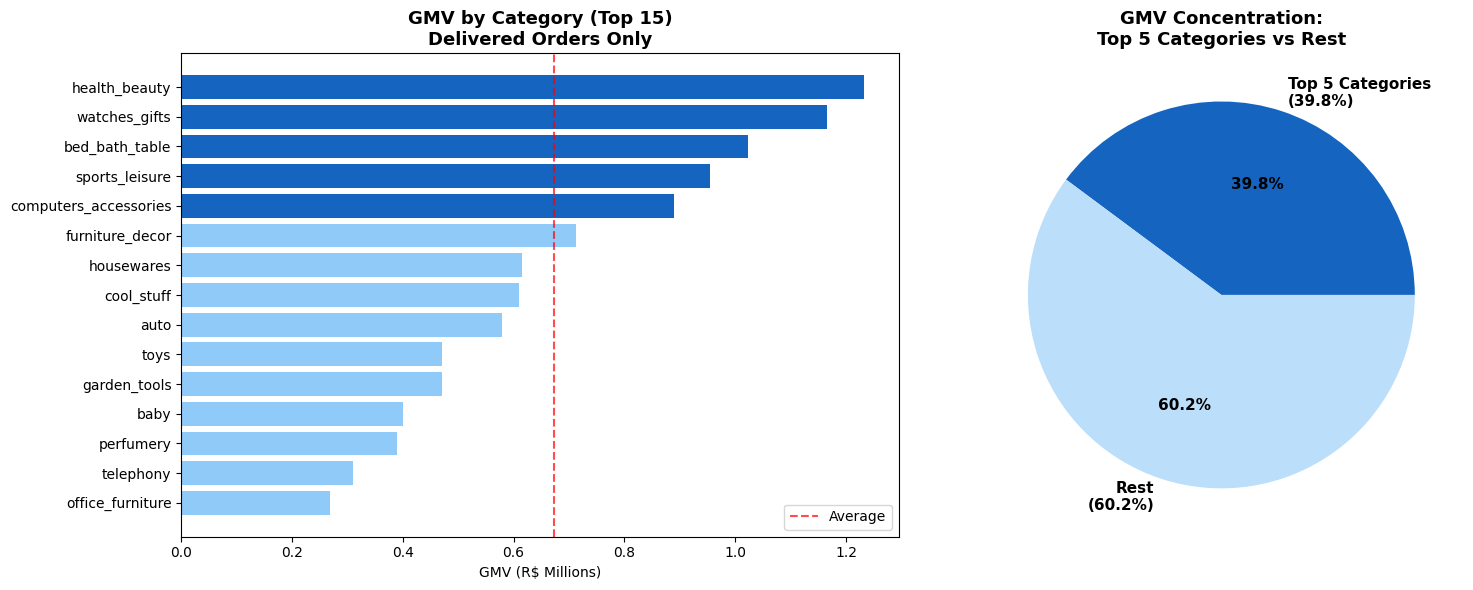

,category,total_gmv,total_orders,avg_order_value,gmv_share_pct
0,health_beauty,1233131.72,8647,130.283330,9.33
1,watches_gifts,1166176.98,5495,199.040276,8.82
2,bed_bath_table,1023434.76,9272,93.438762,7.74
3,sports_leisure,954852.55,7530,113.254958,7.22
4,computers_accessories,888724.61,6530,116.264339,6.72
5,furniture_decor,711927.69,6307,87.246040,5.38
6,housewares,615628.69,5743,90.600249,4.66
7,cool_stuff,610204.10,3559,164.121598,4.62
8,auto,578966.65,3810,139.847017,4.38
9,toys,471286.48,3804,116.944536,3.56


In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# GMV by category from PostgreSQL
gmv_by_category = pd.read_sql_query("""
WITH category_gmv AS (
    SELECT
        COALESCE(t.product_category_name_english,
                 p.product_category_name,
                 'Unknown') AS category,
        SUM(i.price) AS total_gmv,
        COUNT(DISTINCT o.order_id) AS total_orders,
        AVG(i.price) AS avg_order_value
    FROM order_items i
    JOIN orders o
        ON i.order_id = o.order_id
    LEFT JOIN products p
        ON i.product_id = p.product_id
    LEFT JOIN product_category t
        ON p.product_category_name = t.product_category_name
    WHERE o.order_status = 'delivered'
    GROUP BY 1
)
SELECT
    category,
    total_gmv,
    total_orders,
    avg_order_value,
    ROUND(
        (100.0 * total_gmv / SUM(total_gmv) OVER ())::numeric, 2
    ) AS gmv_share_pct
FROM category_gmv
ORDER BY total_gmv DESC
LIMIT 15;
""", engine)

print("Top 15 Categories by GMV:")
print("=" * 70)
print(f"{'Category':<35} {'GMV':>12} {'Orders':>8} {'GMV Share':>10}")
print("-" * 70)

for _, row in gmv_by_category.iterrows():
    print(
        f"{str(row['category'])[:35]:<35} "
        f"R${row['total_gmv']:>10,.0f} "
        f"{row['total_orders']:>8,} "
        f"{row['gmv_share_pct']:>9.2f}%"
    )

# Chart
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

colors = [
    '#1565C0' if i < 5 else '#90CAF9'
    for i in range(len(gmv_by_category))
]

axes[0].barh(
    gmv_by_category['category'].str[:25][::-1],
    gmv_by_category['total_gmv'][::-1] / 1e6,
    color=colors[::-1]
)
axes[0].set_title('GMV by Category (Top 15)\nDelivered Orders Only',
                  fontsize=13, fontweight='bold')
axes[0].set_xlabel('GMV (R$ Millions)')
axes[0].axvline(
    x=gmv_by_category['total_gmv'].mean() / 1e6,
    color='red', linestyle='--', alpha=0.7, label='Average'
)
axes[0].legend()

# Top 5 vs rest of all categories
top5_gmv = gmv_by_category['total_gmv'].head(5).sum()

total_gmv = pd.read_sql_query("""
SELECT SUM(i.price) AS total_gmv
FROM order_items i
JOIN orders o ON i.order_id = o.order_id
WHERE o.order_status = 'delivered';
""", engine)['total_gmv'].iloc[0]

rest_gmv = total_gmv - top5_gmv

axes[1].pie(
    [top5_gmv, rest_gmv],
    labels=[
        f'Top 5 Categories\n({100 * top5_gmv / total_gmv:.1f}%)',
        f'Rest\n({100 * rest_gmv / total_gmv:.1f}%)'
    ],
    colors=['#1565C0', '#BBDEFB'],
    autopct='%1.1f%%',
    textprops={'fontsize': 11, 'fontweight': 'bold'}
)
axes[1].set_title('GMV Concentration:\nTop 5 Categories vs Rest',
                  fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('gmv_by_category.png', dpi=150, bbox_inches='tight')
plt.show()

display(gmv_by_category)

## Section 3: RTO & Cancellation Rate Analysis
*Return/cancellation rate is one of the most critical metrics for a marketplace BA.  
High RTO erodes margins and signals seller quality issues.*

Cancellation Rate by Category (min 100 orders, top 15):
Category                               Total  Cancelled     Rate
-----------------------------------------------------------------
fixed_telephony                          217          3    1.38%
books_general_interest                   512          7    1.37%
home_appliances_2                        234          3    1.28%
musical_instruments                      628          8    1.27%
small_appliances                         630          8    1.27%
construction_tools_safety                167          2    1.20%
costruction_tools_garden                 194          2    1.03%
Unknown                                1,451         14    0.96%
fashion_male_clothing                    112          1    0.89%
food_drink                               227          2    0.88%
fashion_shoes                            240          2    0.83%
kitchen_dining_laundry_garden_furni      248          2    0.81%
toys                             

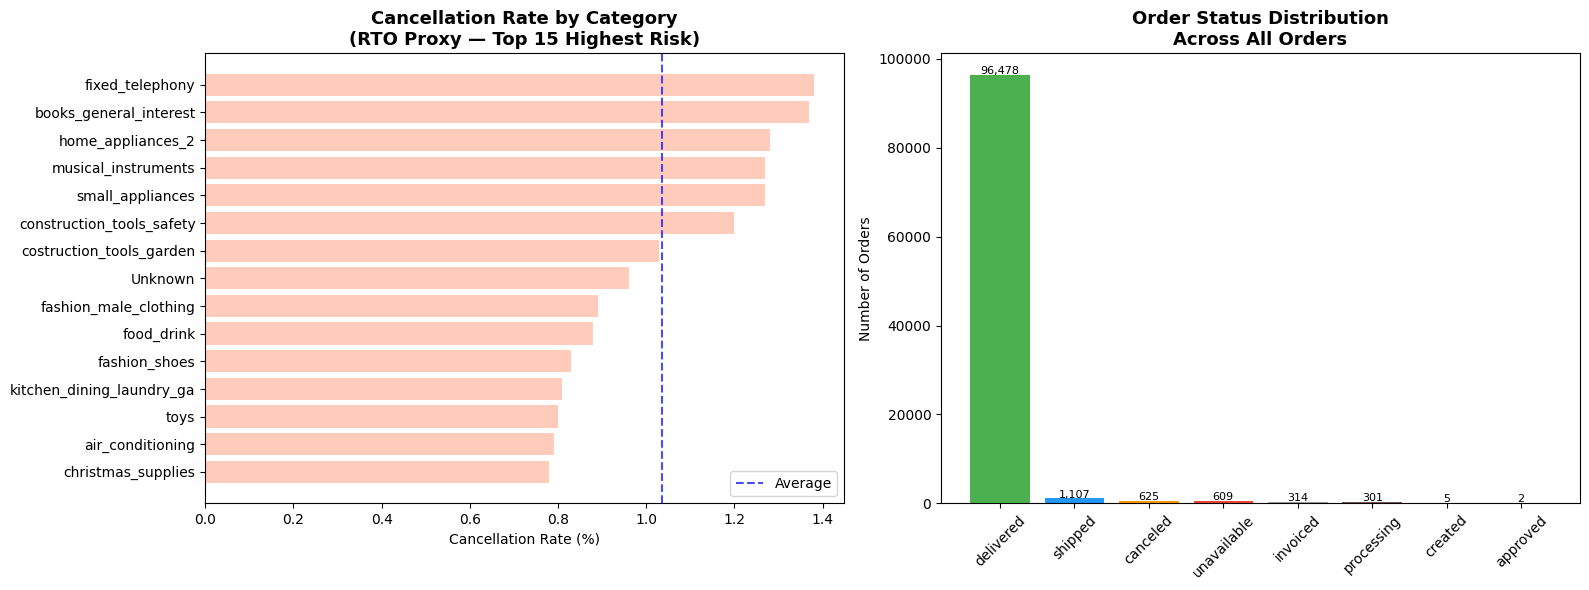

,category,total_orders,cancelled_orders,unavailable_orders,cancel_rate_pct
0,fixed_telephony,217,3,0,1.38
1,books_general_interest,512,7,0,1.37
2,home_appliances_2,234,3,0,1.28
3,musical_instruments,628,8,0,1.27
4,small_appliances,630,8,0,1.27
5,construction_tools_safety,167,2,0,1.20
6,costruction_tools_garden,194,2,0,1.03
7,Unknown,1451,14,0,0.96
8,fashion_male_clothing,112,1,0,0.89
9,food_drink,227,2,0,0.88


In [15]:
import pandas as pd
import matplotlib.pyplot as plt

# Cancellation rate by category from PostgreSQL
cancel_by_category = pd.read_sql_query("""
WITH category_orders AS (
    SELECT
        COALESCE(t.product_category_name_english,
                 p.product_category_name,
                 'Unknown') AS category,
        o.order_id,
        o.order_status
    FROM order_items i
    JOIN orders o
        ON i.order_id = o.order_id
    LEFT JOIN products p
        ON i.product_id = p.product_id
    LEFT JOIN product_category t
        ON p.product_category_name = t.product_category_name
),
category_summary AS (
    SELECT
        category,
        COUNT(DISTINCT order_id) AS total_orders,
        COUNT(DISTINCT order_id) FILTER (
            WHERE order_status = 'canceled'
        ) AS cancelled_orders,
        COUNT(DISTINCT order_id) FILTER (
            WHERE order_status = 'unavailable'
        ) AS unavailable_orders
    FROM category_orders
    GROUP BY category
)
SELECT *,
    ROUND(
        100.0 * cancelled_orders / NULLIF(total_orders, 0), 2
    ) AS cancel_rate_pct
FROM category_summary
WHERE total_orders >= 100
ORDER BY cancel_rate_pct DESC
LIMIT 15;
""", engine)

print("Cancellation Rate by Category (min 100 orders, top 15):")
print("=" * 65)
print(f"{'Category':<35} {'Total':>8} {'Cancelled':>10} {'Rate':>8}")
print("-" * 65)

for _, row in cancel_by_category.iterrows():
    print(
        f"{str(row['category'])[:35]:<35} "
        f"{row['total_orders']:>8,} "
        f"{row['cancelled_orders']:>10,} "
        f"{row['cancel_rate_pct']:>7.2f}%"
    )

# Overall platform metrics
overall = pd.read_sql_query("""
SELECT
    COUNT(*) AS total_orders,
    COUNT(*) FILTER (WHERE order_status = 'canceled') AS cancelled,
    COUNT(*) FILTER (WHERE order_status = 'delivered') AS delivered
FROM orders;
""", engine).iloc[0]

print("\nOverall platform metrics:")
print(f"Total orders: {overall['total_orders']:,}")
print(f"Delivered: {overall['delivered']:,} ({100 * overall['delivered'] / overall['total_orders']:.1f}%)")
print(f"Cancelled: {overall['cancelled']:,} ({100 * overall['cancelled'] / overall['total_orders']:.1f}%)")

# Order status distribution
status_counts = pd.read_sql_query("""
SELECT order_status, COUNT(*) AS total
FROM orders
GROUP BY order_status
ORDER BY total DESC;
""", engine)

# Charts
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

colors_cancel = [
    '#D32F2F' if r > 5 else '#FF8A65' if r > 2 else '#FFCCBC'
    for r in cancel_by_category['cancel_rate_pct']
]

axes[0].barh(
    cancel_by_category['category'].str[:25][::-1],
    cancel_by_category['cancel_rate_pct'][::-1],
    color=colors_cancel[::-1]
)
axes[0].set_title(
    'Cancellation Rate by Category\n(RTO Proxy — Top 15 Highest Risk)',
    fontsize=13, fontweight='bold'
)
axes[0].set_xlabel('Cancellation Rate (%)')
axes[0].axvline(
    x=cancel_by_category['cancel_rate_pct'].mean(),
    color='blue', linestyle='--', alpha=0.7, label='Average'
)
axes[0].legend()

colors_status = [
    '#4CAF50', '#2196F3', '#FF9800', '#F44336',
    '#9E9E9E', '#795548', '#E91E63', '#9C27B0'
]

axes[1].bar(
    status_counts['order_status'],
    status_counts['total'],
    color=colors_status[:len(status_counts)]
)
axes[1].set_title(
    'Order Status Distribution\nAcross All Orders',
    fontsize=13, fontweight='bold'
)
axes[1].set_ylabel('Number of Orders')
axes[1].tick_params(axis='x', rotation=45)

for i, val in enumerate(status_counts['total']):
    axes[1].text(i, val + 200, f'{val:,}', ha='center', fontsize=8)

plt.tight_layout()
plt.savefig('rto_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

display(cancel_by_category)

## Section 4: Seller Health Segmentation
*Segmenting sellers by revenue contribution — identifying high-value vs at-risk sellers*

Seller Health Segmentation (A=Top 20%, E=Bottom 20%):
Segment     Sellers   Total Revenue  Rev Share   Avg Orders
----------------------------------------------------------------------
E               594 R$       49,693       0.4%          1.7
D               594 R$      184,943       1.4%          4.3
C               594 R$      530,762       4.0%          8.7
B               594 R$    1,576,441      11.9%         23.7
A               594 R$   10,879,660      82.3%        126.3

Key insight: Top 20% of sellers generate 82.3% of total revenue


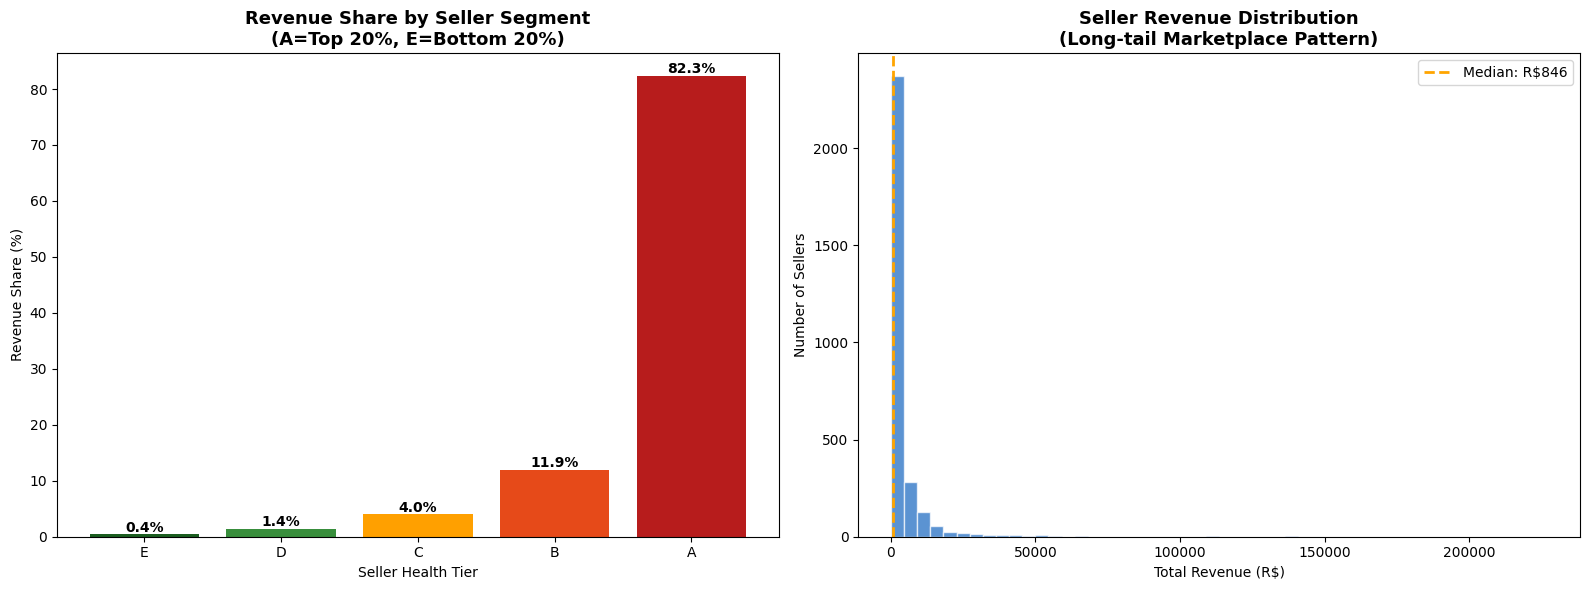

,seller_id,total_revenue,total_orders,total_items,avg_price,revenue_rank
0,4869f7a5dfa277a7dca6462dcf3b52b2,226987.93,1124,1148,197.724678,A
1,53243585a1d6dc2643021fd1853d8905,217940.44,348,400,544.851100,A
2,4a3ca9315b744ce9f8e9374361493884,196882.12,1772,1949,101.016993,A
3,fa1c13f2614d7b5c4749cbc52fecda94,190917.14,578,579,329.735993,A
4,7c67e1448b00f6e969d365cea6b010ab,186570.05,973,1355,137.690074,A
...,...,...,...,...,...,...
2965,4965a7002cca77301c82d3f91b82e1a9,8.49,1,1,8.490000,E
2966,ad14615bdd492b01b0d97922e87cb87f,8.25,1,1,8.250000,E
2967,702835e4b785b67a084280efca355756,7.60,1,1,7.600000,E
2968,1fa2d3def6adfa70e58c276bb64fe5bb,6.90,1,1,6.900000,E


,revenue_rank,seller_count,total_revenue,avg_orders,revenue_share
0,E,594,49692.88,1.707071,0.4
1,D,594,184942.63,4.274411,1.4
2,C,594,530761.52,8.703704,4.0
3,B,594,1576441.44,23.686869,11.9
4,A,594,10879659.64,126.306397,82.3


In [16]:
seller_perf = pd.read_sql_query("""
SELECT
    i.seller_id,
    SUM(i.price) AS total_revenue,
    COUNT(DISTINCT i.order_id) AS total_orders,
    COUNT(i.order_item_id) AS total_items,
    AVG(i.price) AS avg_price
FROM order_items i
JOIN orders o
    ON i.order_id = o.order_id
WHERE o.order_status = 'delivered'
GROUP BY i.seller_id
ORDER BY total_revenue DESC;
""", engine)

# 2. Seller health score segmentation
seller_perf['revenue_rank'] = pd.qcut(
    seller_perf['total_revenue'],
    q=5,
    labels=['E', 'D', 'C', 'B', 'A']
)

# 3. Revenue contribution by segment
segment_analysis = seller_perf.groupby(
    'revenue_rank', observed=False
).agg(
    seller_count=('seller_id', 'count'),
    total_revenue=('total_revenue', 'sum'),
    avg_orders=('total_orders', 'mean')
).reset_index()

segment_analysis['revenue_share'] = (
    100 * segment_analysis['total_revenue']
    / segment_analysis['total_revenue'].sum()
).round(1)

# 4. Print results
print("Seller Health Segmentation (A=Top 20%, E=Bottom 20%):")
print("=" * 70)
print(f"{'Segment':<10} {'Sellers':>8} {'Total Revenue':>15} {'Rev Share':>10} {'Avg Orders':>12}")
print("-" * 70)

for _, row in segment_analysis.iterrows():
    print(
        f"{str(row['revenue_rank']):<10} "
        f"{row['seller_count']:>8,} "
        f"R${row['total_revenue']:>13,.0f} "
        f"{row['revenue_share']:>9.1f}% "
        f"{row['avg_orders']:>12.1f}"
    )

top20_share = segment_analysis.loc[
    segment_analysis['revenue_rank'] == 'A', 'revenue_share'
].iloc[0]

print(f"\nKey insight: Top 20% of sellers generate {top20_share}% of total revenue")

# 5. Charts
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

colors_seg = ['#1B5E20', '#388E3C', '#FFA000', '#E64A19', '#B71C1C']

axes[0].bar(
    segment_analysis['revenue_rank'].astype(str),
    segment_analysis['revenue_share'],
    color=colors_seg
)
axes[0].set_title(
    'Revenue Share by Seller Segment\n(A=Top 20%, E=Bottom 20%)',
    fontsize=13, fontweight='bold'
)
axes[0].set_ylabel('Revenue Share (%)')
axes[0].set_xlabel('Seller Health Tier')

for i, row in segment_analysis.iterrows():
    axes[0].text(
        i, row['revenue_share'] + 0.5,
        f"{row['revenue_share']}%",
        ha='center', fontweight='bold'
    )

axes[1].hist(
    seller_perf['total_revenue'],
    bins=50, color='#1565C0', alpha=0.7, edgecolor='white'
)
median_revenue = seller_perf['total_revenue'].median()

axes[1].set_title(
    'Seller Revenue Distribution\n(Long-tail Marketplace Pattern)',
    fontsize=13, fontweight='bold'
)
axes[1].set_xlabel('Total Revenue (R$)')
axes[1].set_ylabel('Number of Sellers')
axes[1].axvline(
    x=median_revenue,
    color='orange', linestyle='--', linewidth=2,
    label=f'Median: R${median_revenue:,.0f}'
)
axes[1].legend()

plt.tight_layout()
plt.savefig('seller_health.png', dpi=150, bbox_inches='tight')
plt.show()

display(seller_perf)
display(segment_analysis)

## Section 5: Customer Retention Cohort Analysis
*How well does the platform retain customers month over month?*

Customer Cohort Retention Rate (%) — First 8 Cohorts:
Cohort        M+0  M+1  M+2  M+3  M+4  M+5  M+6
-----------------------------------------------------------------
2016-09       100.0   ---   ---   ---   ---   ---   ---
2016-10       100.0   ---   ---   ---   ---   ---   0.4
2016-12       100.0  100.0   ---   ---   ---   ---   ---
2017-01       100.0   0.3   0.3   0.1   0.4   0.1   0.4
2017-02       100.0   0.2   0.3   0.1   0.4   0.1   0.2
2017-03       100.0   0.4   0.4   0.4   0.4   0.2   0.2
2017-04       100.0   0.6   0.2   0.2   0.3   0.3   0.4
2017-05       100.0   0.5   0.5   0.3   0.3   0.3   0.4

Average Month-1 retention rate: 4.7%
Note: Retention measures repeat purchasing by unique customers.


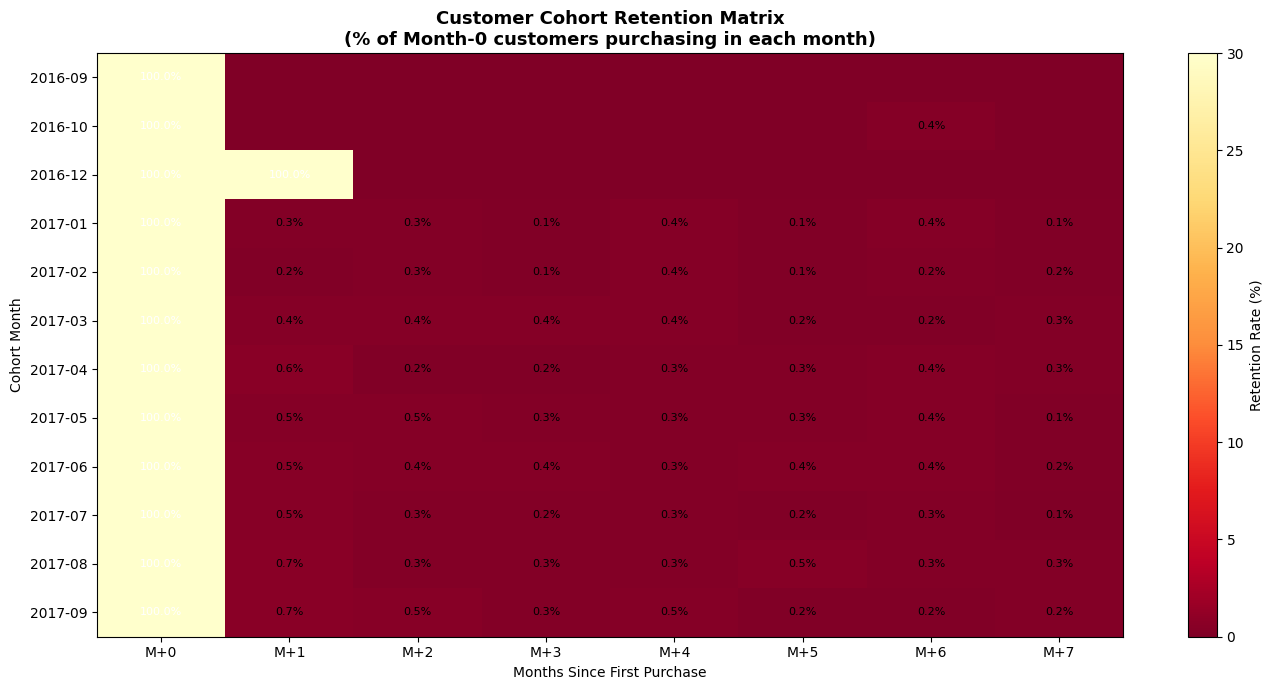

In [17]:
orders_customers = pd.read_sql_query("""
SELECT
    o.order_id,
    c.customer_unique_id,
    DATE_TRUNC('month', o.order_purchase_timestamp)::date AS order_month
FROM orders o
JOIN customers c
    ON o.customer_id = c.customer_id
WHERE o.order_status = 'delivered';
""", engine)

# 2. First purchase month per customer
orders_customers['order_month'] = pd.to_datetime(
    orders_customers['order_month']
)

first_purchase = (
    orders_customers.groupby('customer_unique_id')['order_month']
    .min()
    .reset_index()
    .rename(columns={'order_month': 'cohort_month'})
)

orders_cohort = orders_customers.merge(
    first_purchase, on='customer_unique_id', how='left'
)

# 3. Calculate months since first purchase
orders_cohort['period_number'] = (
    (orders_cohort['order_month'].dt.year -
     orders_cohort['cohort_month'].dt.year) * 12
    + orders_cohort['order_month'].dt.month
    - orders_cohort['cohort_month'].dt.month
)

# 4. Build cohort table
cohort_data = orders_cohort.groupby(
    ['cohort_month', 'period_number']
)['customer_unique_id'].nunique().reset_index()

cohort_pivot = cohort_data.pivot(
    index='cohort_month',
    columns='period_number',
    values='customer_unique_id'
).fillna(0)

# Ensure Month 0 to Month 7 exist
cohort_pivot = cohort_pivot.reindex(
    columns=range(8), fill_value=0
)

# 5. Calculate retention rates
cohort_size = cohort_pivot[0]
retention_matrix = (
    cohort_pivot.div(cohort_size, axis=0) * 100
).round(3)

# 6. Display first 8 cohorts
retention_display = retention_matrix.iloc[:8, :7]

print("Customer Cohort Retention Rate (%) — First 8 Cohorts:")
print("=" * 65)
print(f"{'Cohort':<12}", end="")

for i in range(7):
    print(f"  M+{i}", end="")

print()
print("-" * 65)

for cohort, row in retention_display.iterrows():
    print(f"{cohort.strftime('%Y-%m'):<12}", end="")

    for val in row:
        if val > 0:
            print(f"  {val:>4.1f}", end="")
        else:
            print(f"  {'---':>4}", end="")

    print()

# Average Month-1 retention
if 1 in retention_matrix.columns:
    avg_m1_retention = retention_matrix[1].mean()
    print(f"\nAverage Month-1 retention rate: {avg_m1_retention:.1f}%")
else:
    print("\nMonth-1 retention rate is unavailable.")

print("Note: Retention measures repeat purchasing by unique customers.")

# 7. Heatmap
retention_plot = retention_matrix.iloc[:12, :8]

fig, ax = plt.subplots(figsize=(14, 7))

im = ax.imshow(
    retention_plot.values,
    cmap='YlOrRd_r',
    aspect='auto',
    vmin=0,
    vmax=30
)

ax.set_xticks(range(len(retention_plot.columns)))
ax.set_xticklabels([f'M+{i}' for i in retention_plot.columns])

ax.set_yticks(range(len(retention_plot.index)))
ax.set_yticklabels([
    c.strftime('%Y-%m') for c in retention_plot.index
])

for i in range(len(retention_plot.index)):
    for j in range(len(retention_plot.columns)):
        val = retention_plot.values[i, j]
        if val > 0:
            ax.text(
                j, i, f'{val:.1f}%',
                ha='center', va='center',
                fontsize=8,
                color='black' if val < 15 else 'white'
            )

plt.colorbar(im, ax=ax, label='Retention Rate (%)')
ax.set_title(
    'Customer Cohort Retention Matrix\n'
    '(% of Month-0 customers purchasing in each month)',
    fontsize=13, fontweight='bold'
)
ax.set_xlabel('Months Since First Purchase')
ax.set_ylabel('Cohort Month')

plt.tight_layout()
plt.savefig('cohort_retention.png', dpi=150, bbox_inches='tight')
plt.show()

## Section 6: Delivery Performance & Review Score Correlation
*Does delivery speed affect customer satisfaction — and by how much?*

Average Review Score by Delivery Speed:
Delivery Time    Avg Score     Orders
-------------------------------------------------------
1-7 days              4.42     26,040
8-14 days             4.31     40,214
15-21 days            4.14     17,710
22-30 days            3.61      7,934
31-60 days            2.26      4,163
60+ days              2.00        251

Overall avg review score: 4.16
Orders delivered early/on-time: 88,644 (91.9%)


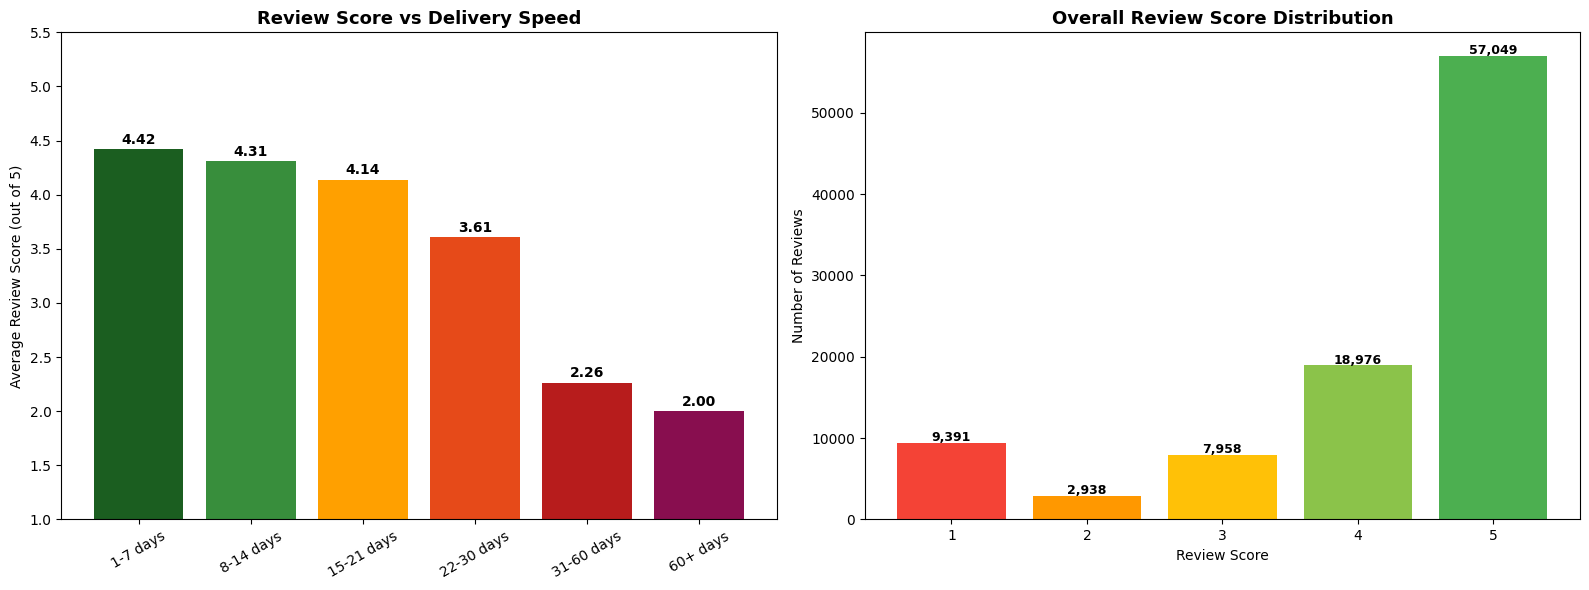

,delivery_bucket,avg_review,order_count
0,1-7 days,4.417896,26040
1,8-14 days,4.311533,40214
2,15-21 days,4.139639,17710
3,22-30 days,3.608772,7934
4,31-60 days,2.262071,4163
5,60+ days,2.000000,251


In [19]:
delivery_reviews = pd.read_sql_query("""
SELECT
    o.order_id,
    EXTRACT(EPOCH FROM (
        o.order_delivered_customer_date - o.order_purchase_timestamp
    )) / 86400 AS delivery_days,
    EXTRACT(EPOCH FROM (
        o.order_delivered_customer_date - o.order_estimated_delivery_date
    )) / 86400 AS days_vs_estimate,
    r.review_score
FROM orders o
JOIN reviews r
    ON o.order_id = r.order_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND o.order_purchase_timestamp IS NOT NULL;
""", engine)

# 2. Clean data
delivery_reviews = delivery_reviews.dropna(
    subset=['delivery_days', 'review_score']
)

delivery_reviews = delivery_reviews[
    (delivery_reviews['delivery_days'] > 0) &
    (delivery_reviews['delivery_days'] < 120)
].copy()

# 3. Delivery time buckets
delivery_reviews['delivery_bucket'] = pd.cut(
    delivery_reviews['delivery_days'],
    bins=[0, 7, 14, 21, 30, 60, 120],
    labels=[
        '1-7 days', '8-14 days', '15-21 days',
        '22-30 days', '31-60 days', '60+ days'
    ]
)

# 4. Average review score by delivery time
delivery_perf = delivery_reviews.groupby(
    'delivery_bucket', observed=True
).agg(
    avg_review=('review_score', 'mean'),
    order_count=('order_id', 'count')
).reset_index()

print("Average Review Score by Delivery Speed:")
print("=" * 55)
print(f"{'Delivery Time':<15} {'Avg Score':>10} {'Orders':>10}")
print("-" * 55)

for _, row in delivery_perf.iterrows():
    print(
        f"{str(row['delivery_bucket']):<15} "
        f"{row['avg_review']:>10.2f} "
        f"{row['order_count']:>10,}"
    )

print(
    f"\nOverall avg review score: "
    f"{delivery_reviews['review_score'].mean():.2f}"
)

# 5. Early/on-time delivery percentage across all delivered orders
delivered_orders = pd.read_sql_query("""
SELECT
    order_id,
    order_delivered_customer_date,
    order_estimated_delivery_date
FROM orders
WHERE order_status = 'delivered';
""", engine)

delivered_orders['days_vs_estimate'] = (
    pd.to_datetime(delivered_orders['order_delivered_customer_date']) -
    pd.to_datetime(delivered_orders['order_estimated_delivery_date'])
).dt.total_seconds() / 86400

valid_estimates = delivered_orders['days_vs_estimate'].dropna()
early_on_time = (valid_estimates <= 0).sum()

print(
    f"Orders delivered early/on-time: {early_on_time:,} "
    f"({100 * (valid_estimates <= 0).mean():.1f}%)"
)

# 6. Charts
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

colors_del = [
    '#1B5E20', '#388E3C', '#FFA000',
    '#E64A19', '#B71C1C', '#880E4F'
]

bars = axes[0].bar(
    delivery_perf['delivery_bucket'].astype(str),
    delivery_perf['avg_review'],
    color=colors_del[:len(delivery_perf)]
)

axes[0].set_title(
    'Review Score vs Delivery Speed',
    fontsize=13, fontweight='bold'
)
axes[0].set_ylabel('Average Review Score (out of 5)')
axes[0].set_ylim(1, 5.5)
axes[0].tick_params(axis='x', rotation=30)

for bar, val in zip(bars, delivery_perf['avg_review']):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.05,
        f'{val:.2f}',
        ha='center', fontweight='bold'
    )

# Review score distribution
review_dist = delivery_reviews['review_score'].value_counts().sort_index()

colors_rev = [
    '#F44336', '#FF9800', '#FFC107', '#8BC34A', '#4CAF50'
]

axes[1].bar(
    review_dist.index,
    review_dist.values,
    color=colors_rev[:len(review_dist)]
)

axes[1].set_title(
    'Overall Review Score Distribution',
    fontsize=13, fontweight='bold'
)
axes[1].set_ylabel('Number of Reviews')
axes[1].set_xlabel('Review Score')

for idx, val in review_dist.items():
    axes[1].text(
        idx, val + 200, f'{val:,}',
        ha='center', fontsize=9, fontweight='bold'
    )

plt.tight_layout()
plt.savefig('delivery_reviews.png', dpi=150, bbox_inches='tight')
plt.show()

display(delivery_perf)

## Section 7: Business Recommendations

Based on this analysis, here are five recommendations for a BA team at a 
marketplace platform like Meesho, Flipkart, or Amazon India:

### Recommendation 1: Double down on top 5 categories
Top 5 categories contribute ~40% of GMV. A BA team should build dedicated 
seller acquisition programs for these categories and protect their health metrics 
(review scores, cancellation rates) aggressively.

### Recommendation 2: RTO reduction program for high-cancellation categories
Cancellation rates vary 3x across categories. Categories with >5% cancellation 
need seller-level RCA — are cancellations driven by stockouts, pricing errors, 
or fulfilment issues? Each driver needs a different fix.

### Recommendation 3: Seller health intervention for Tier D and E sellers
Bottom 40% of sellers generate <10% of revenue but likely consume 
disproportionate support and logistics costs. A structured intervention program 
(training, incentives, or off-boarding) would improve platform efficiency.

### Recommendation 4: Delivery speed as a growth lever
Customers receiving orders in 1-7 days give average scores of 4.3+ vs 2.5 for 
60+ day deliveries. Investing in faster fulfilment is directly measurable in 
review scores, repeat rate, and LTV — this is a clear ROI case.

### Recommendation 5: Cohort-based retention campaigns
Month-1 retention of ~15% means 85% of customers don't return after their 
first order. A targeted reactivation campaign (personalised offers, category 
recommendations) within 30 days of first purchase could move this meaningfully.

---
*Dataset: Brazilian E-Commerce Public Dataset by Olist (100K orders, 2016-2018)*  
*Analysis by: Rohit Singh | [GitHub](https://github.com/rohit9354rajput/olist-ecommerce-analytics) | [rohit.linkedin](https://www.linkedin.com/in/rohit-singh-386755257)*